In [1]:
# =====================================================
# 1. IMPORTS & GLOBAL CONFIGURATION
# =====================================================

import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn core utilities
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    RandomizedSearchCV,
)
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
)

# Persistence & display
import joblib
from IPython.display import display

pd.set_option("display.max_columns", None)
print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# =====================================================
# 1.1 LOAD DATASET
# =====================================================

df = pd.read_csv("Extended_Employee_Performance_and_Productivity_Data.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (100000, 20)


In [3]:
# =====================================================
# 1.2 DATA CLEANING (Pandas 2+ safe)
# =====================================================
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())
for col in df.select_dtypes(include='string').columns:
    df[col] = df[col].fillna(df[col].mode()[0])
print("Missing values handled successfully.")

Missing values handled successfully.


In [4]:
# =====================================================
# 1.3 NORMALIZATION
# =====================================================
scaler = MinMaxScaler()
columns_to_scale = [
    'Training_Hours',
    'Projects_Handled',
    'Overtime_Hours',
    'Sick_Days',
    'Remote_Work_Frequency',
    'Performance_Score'
]
df[columns_to_scale] = scaler.fit_transform(df[columns_to_scale])
print("Normalization completed successfully.")

Normalization completed successfully.


In [5]:
# =====================================================
# 1.4 FEATURE ENGINEERING
# =====================================================

# Historical Task Success (Target for ML)
df['Historical_Task_Success'] = (
    0.5 * df['Performance_Score'] +
    0.3 * df['Training_Hours'] +
    0.2 * df['Projects_Handled']
)

print("Feature engineering completed (Historical_Task_Success created).")


Feature engineering completed (Historical_Task_Success created).


In [6]:
# =====================================================
# 4. BASELINE MODEL TRAINING
# =====================================================

features = [
    'Training_Hours',
    'Projects_Handled',
    'Overtime_Hours',
    'Sick_Days',
    'Remote_Work_Frequency',
    'Performance_Score'
]

X = df[features]
y = df['Historical_Task_Success']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

model = RandomForestRegressor(
    n_estimators=400,
    max_depth=12,
    random_state=42
)

model.fit(X_train, y_train)

print("Baseline model trained successfully.")

y_true = y_test
y_pred = model.predict(X_test)
r2 = r2_score(y_true, y_pred)
print("Baseline R² Score:", r2)

Baseline model trained successfully.
Baseline R² Score: 0.9999480964361217


In [7]:
# =====================================================
# PROFILE MATCH SCORE
# =====================================================

def profile_match_score(df, task):

    df_copy = df.copy()

    df_copy['Skill_Match'] = 1 - abs(
        df_copy['Training_Hours'] - task['required_skill_level']
    )

    df_copy['Experience_Match'] = 1 - abs(
        df_copy['Projects_Handled'] - task['required_experience_level']
    )

    df_copy['Performance_Match'] = 1 - abs(
        df_copy['Performance_Score'] - task['required_performance_level']
    )

    profile_score = (
        0.5 * df_copy['Skill_Match'] +
        0.3 * df_copy['Experience_Match'] +
        0.2 * df_copy['Performance_Match']
    )

    return profile_score.clip(0, 1)

In [8]:
# =====================================================
# AVAILABILITY SCORE
# =====================================================

def availability_score(df):

    score = (
        1 - (
            0.4 * df['Projects_Handled'] +
            0.3 * df['Overtime_Hours'] +
            0.3 * df['Sick_Days']
        )
    )

    return score.clip(0, 1)


In [9]:
# =====================================================
# HISTORICAL PERFORMANCE SCORE
# =====================================================

def historical_performance_score(df):

    score = (
        0.6 * df['Performance_Score'] +
        0.4 * df['Projects_Handled']
    )

    return score.clip(0, 1)


In [10]:
# =====================================================
# MAIN RECOMMENDATION FUNCTION
# =====================================================

def recommend_resources(task, df, model, top_n=5):

    df_copy = df.copy()

    # ML Success Prediction
    df_copy['ML_Success'] = model.predict(df_copy[features])

    # Profile Match
    df_copy['Profile_Score'] = profile_match_score(df_copy, task)

    # Availability
    df_copy['Availability_Score_New'] = availability_score(df_copy)

    # Historical Performance
    df_copy['Historical_Performance'] = historical_performance_score(df_copy)

    # FINAL GRADE CALCULATION
    df_copy['Final_Grade'] = (
        0.30 * df_copy['Profile_Score'] +
        0.25 * df_copy['Availability_Score_New'] +
        0.25 * df_copy['Historical_Performance'] +
        0.20 * df_copy['ML_Success']
    )

    # Normalize to 0–100
    scaler_final = MinMaxScaler()
    df_copy['Final_Grade'] = scaler_final.fit_transform(
        df_copy[['Final_Grade']]
    ) * 100

    df_copy = df_copy.sort_values(
        by='Final_Grade',
        ascending=False
    )

    return df_copy.head(top_n)

In [11]:
def explain_candidate(row):

    explanation = f"""
    Final Grade: {row['Final_Grade']:.2f}/100

    Profile Match Score: {row['Profile_Score']:.3f}
    Availability Score: {row['Availability_Score_New']:.3f}
    Historical Performance: {row['Historical_Performance']:.3f}
    ML Success Prediction: {row['ML_Success']:.3f}
    """

    return explanation


In [12]:
# =====================================================
# EXAMPLE TASK REQUIREMENTS
# =====================================================

task_input = {
    "required_skill_level": 0.7,
    "required_experience_level": 0.6,
    "required_performance_level": 0.8
}


In [13]:
# =====================================================
# 8. QUICK ENGINE RUN (BASELINE MODEL)
#    (Optional: for a fast check before tuning)
# =====================================================

recommendations = recommend_resources(task_input, df, model, top_n=20)

print("\nTop 20 Recommended Employees (current model):")
display(recommendations[['Employee_ID', 'Final_Grade', 'Profile_Score', 'Availability_Score_New', 'Historical_Performance', 'ML_Success']])

print("\nTop Candidate Explanation:")
print(explain_candidate(recommendations.iloc[0]))


Top 20 Recommended Employees (current model):


,Employee_ID,Final_Grade,Profile_Score,Availability_Score_New,Historical_Performance,ML_Success
62520,62521,100.000000,0.916056,0.706122,0.893878,0.857755
84595,84596,99.707454,0.954016,0.731492,0.836735,0.831268
45340,45341,99.167174,0.885753,0.706122,0.893878,0.876833
71570,71571,99.034499,0.939812,0.750739,0.828571,0.817405
86167,86168,98.986945,0.896164,0.736594,0.853061,0.868441
39768,39769,98.885328,0.938864,0.721147,0.836735,0.840888
42554,42555,98.771787,0.939660,0.723329,0.844898,0.823168
97610,97611,98.619798,0.926467,0.704821,0.853061,0.851075
74845,74846,98.561914,0.861264,0.673469,0.926531,0.894398
23877,23878,98.546998,0.910396,0.777410,0.812245,0.833159



Top Candidate Explanation:

    Final Grade: 100.00/100

    Profile Match Score: 0.916
    Availability Score: 0.706
    Historical Performance: 0.894
    ML Success Prediction: 0.858
    


In [14]:
# =====================================================
# 2. EXPLORATORY DATA ANALYSIS (EDA)
#    (Run after loading and basic cleaning)
# =====================================================

print("Dataset shape:", df.shape)

print("\nColumn types:")
print(df.dtypes)

print("\nMissing values per column (top 20):")
print(df.isna().sum().sort_values(ascending=False).head(20))

numeric_cols = df.select_dtypes(include=np.number).columns
print("\nNumeric columns:", numeric_cols.tolist())

# Summary statistics for numeric columns
df[numeric_cols].describe().T

Dataset shape: (100000, 21)

Column types:
Employee_ID                      int64
Department                         str
Gender                             str
Age                              int64
Job_Title                          str
Hire_Date                          str
Years_At_Company                 int64
Education_Level                    str
Performance_Score              float64
Monthly_Salary                 float64
Work_Hours_Per_Week              int64
Projects_Handled               float64
Overtime_Hours                 float64
Sick_Days                      float64
Remote_Work_Frequency          float64
Team_Size                        int64
Training_Hours                 float64
Promotions                       int64
Employee_Satisfaction_Score    float64
Resigned                          bool
Historical_Task_Success        float64
dtype: object

Missing values per column (top 20):
Employee_ID                    0
Projects_Handled               0
Resigned             

,count,mean,std,min,25%,50%,75%,max
Employee_ID,100000.0,50000.500000,28867.657797,1.0,25000.750000,50000.500000,75000.250000,100000.0
Age,100000.0,41.029410,11.244121,22.0,31.000000,41.000000,51.000000,60.0
Years_At_Company,100000.0,4.476070,2.869336,0.0,2.000000,4.000000,7.000000,10.0
Performance_Score,100000.0,0.498858,0.353681,0.0,0.250000,0.500000,0.750000,1.0
Monthly_Salary,100000.0,6403.211000,1372.508717,3850.0,5250.000000,6500.000000,7500.000000,9000.0
Work_Hours_Per_Week,100000.0,44.956950,8.942003,30.0,37.000000,45.000000,53.000000,60.0
Projects_Handled,100000.0,0.498595,0.295298,0.0,0.244898,0.489796,0.755102,1.0
Overtime_Hours,100000.0,0.500515,0.298760,0.0,0.241379,0.517241,0.758621,1.0
Sick_Days,100000.0,0.500611,0.309399,0.0,0.214286,0.500000,0.785714,1.0
Remote_Work_Frequency,100000.0,0.500905,0.353512,0.0,0.250000,0.500000,0.750000,1.0


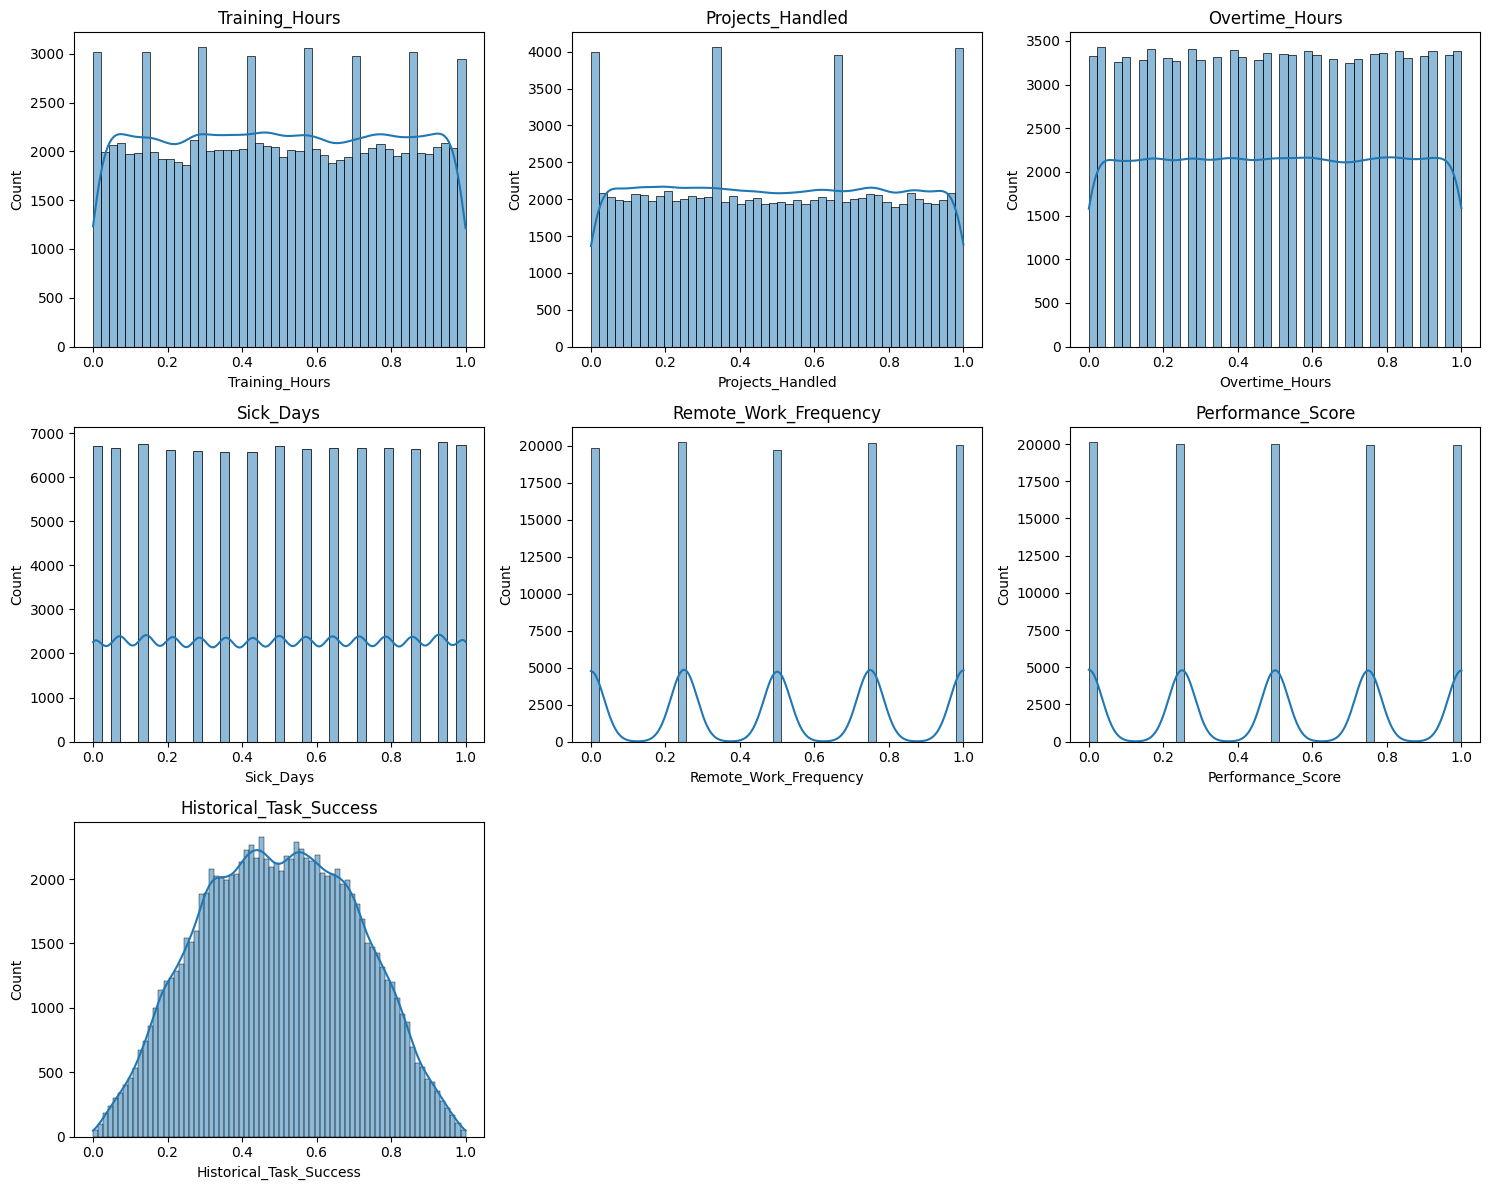

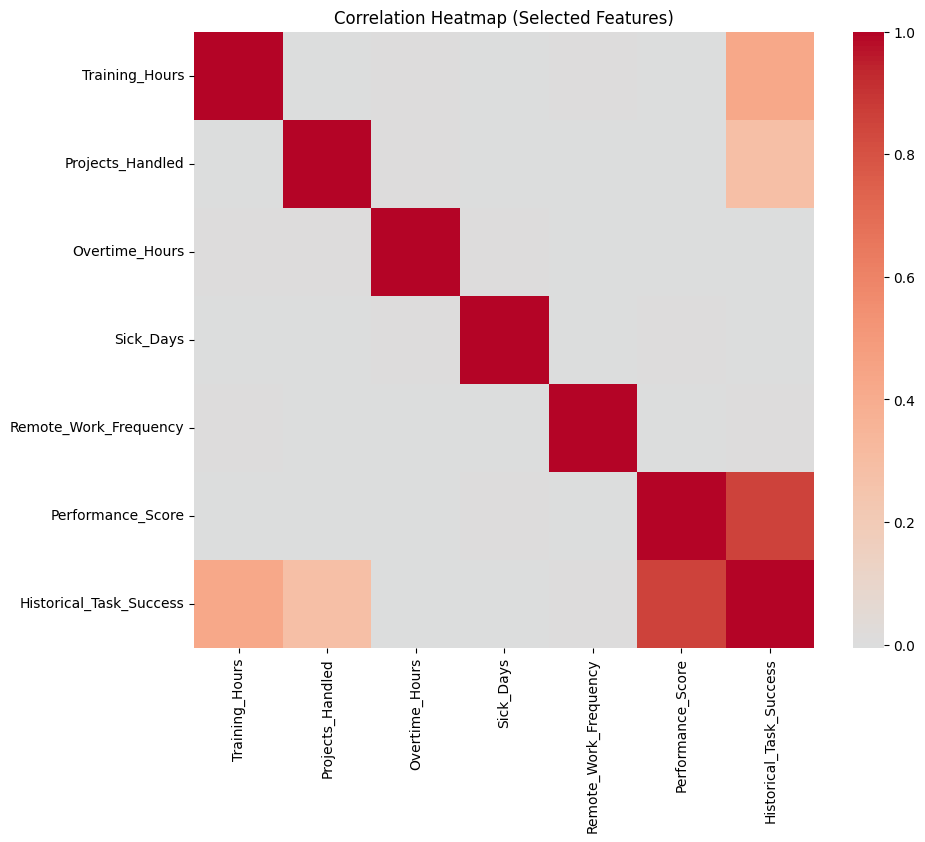

In [15]:
# =====================================================
# 3. EDA VISUALIZATIONS
# (Note: some features are already normalized to 0–1)
# =====================================================

key_numeric = [
    'Training_Hours',
    'Projects_Handled',
    'Overtime_Hours',
    'Sick_Days',
    'Remote_Work_Frequency',
    'Performance_Score',
    'Historical_Task_Success'
]

available = [c for c in key_numeric if c in df.columns]

n = len(available)
rows = int(np.ceil(n / 3)) or 1

plt.figure(figsize=(15, 4 * rows))
for i, col in enumerate(available, 1):
    plt.subplot(rows, 3, i)
    sns.histplot(df[col], kde=True)
    plt.title(col)
plt.tight_layout()
plt.show()

# Correlation heatmap for selected features
plt.figure(figsize=(10, 8))
correlation = df[available].corr()
sns.heatmap(correlation, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Selected Features)")
plt.show()

In [16]:
# =====================================================
# 4. BASELINE MODEL: DETAILED EVALUATION METRICS
# =====================================================

# Reuse y_test and model from the training cell
y_true = y_test
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)

print("Baseline RandomForestRegressor performance on test set:")
print(f"R²:   {r2_score(y_true, y_pred):.6f}")
print(f"MAE:  {mae:.6f}")
print(f"MSE:  {mse:.6f}")
print(f"RMSE: {rmse:.6f}")

Baseline RandomForestRegressor performance on test set:
R²:   0.999948
MAE:  0.001136
MSE:  0.000002
RMSE: 0.001489


In [17]:
# =====================================================
# 5. CROSS-VALIDATION FOR BASELINE MODEL
# =====================================================

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print("Cross-validated R² scores:", cv_scores)
print("Mean CV R²:", cv_scores.mean())
print("Std CV R²:", cv_scores.std())

Cross-validated R² scores: [0.99994602 0.99994642 0.99994745 0.99994965 0.99994889]
Mean CV R²: 0.9999476836541106
Std CV R²: 1.3962516502025082e-06


In [18]:
# =====================================================
# 6. LIGHTWEIGHT HYPERPARAMETER TUNING (RandomizedSearchCV)
#    Optimized for speed and lower CPU usage
# =====================================================

# Use a smaller subset of the training data for tuning to speed things up
X_tune, _, y_tune, _ = train_test_split(
    X_train, y_train,
    test_size=0.7,
    random_state=42,
)

rf_base = RandomForestRegressor(random_state=42, n_jobs=2)

param_distributions = {
    "n_estimators": [200, 300],
    "max_depth": [None, 10, 16],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"],
}

random_search = RandomizedSearchCV(
    rf_base,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="r2",
    cv=3,
    n_jobs=2,
    random_state=42,
    verbose=1,
)

random_search.fit(X_tune, y_tune)

print("Best parameters (lightweight search):")
print(random_search.best_params_)
print("\nBest cross-validated R²:", random_search.best_score_)

best_model = random_search.best_estimator_

# Evaluate tuned model on the held-out test set
y_pred_best = best_model.predict(X_test)

mae_best = mean_absolute_error(y_test, y_pred_best)
mse_best = mean_squared_error(y_test, y_pred_best)
rmse_best = np.sqrt(mse_best)
r2_best = r2_score(y_test, y_pred_best)

print("\nTuned RandomForestRegressor performance on test set (lightweight search):")
print(f"R²:   {r2_best:.6f}")
print(f"MAE:  {mae_best:.6f}")
print(f"MSE:  {mse_best:.6f}")
print(f"RMSE: {rmse_best:.6f}")

# Use tuned model as the default model for downstream cells
model = best_model

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters (lightweight search):
{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 16}

Best cross-validated R²: 0.997951808774198

Tuned RandomForestRegressor performance on test set (lightweight search):
R²:   0.998333
MAE:  0.006357
MSE:  0.000071
RMSE: 0.008437


In [19]:
# =====================================================
# 7. SAVE FINAL MODEL AND RUN ENGINE WITH IT
# =====================================================

# Use tuned model if available (set in the tuning cell), otherwise fall back to baseline model
final_model = model

MODEL_PATH = "resource_recommendation_model.joblib"
joblib.dump(final_model, MODEL_PATH)
print(f"Saved resource recommendation model to {MODEL_PATH}")

# Run recommendation engine with the final model
recommendations_final = recommend_resources(task_input, df, final_model, top_n=20)

print("\nTop 20 Recommended Employees (using final model):")
cols_to_show = [
    'Employee_ID',
    'Final_Grade',
    'Profile_Score',
    'Availability_Score_New',
    'Historical_Performance',
    'ML_Success',
]
available_cols = [c for c in cols_to_show if c in recommendations_final.columns]

display(recommendations_final[available_cols])

print("\nTop Candidate Explanation:")
print(explain_candidate(recommendations_final.iloc[0]))

Saved resource recommendation model to resource_recommendation_model.joblib

Top 20 Recommended Employees (using final model):


,Employee_ID,Final_Grade,Profile_Score,Availability_Score_New,Historical_Performance,ML_Success
62520,62521,100.000000,0.916056,0.706122,0.893878,0.851451
84595,84596,99.674481,0.954016,0.731492,0.836735,0.824050
71570,71571,99.120887,0.939812,0.750739,0.828571,0.814190
42554,42555,98.988441,0.939660,0.723329,0.844898,0.824131
86167,86168,98.943557,0.896164,0.736594,0.853061,0.861186
39768,39769,98.878653,0.938864,0.721147,0.836735,0.834823
45340,45341,98.863119,0.885753,0.706122,0.893878,0.861355
97610,97611,98.845408,0.926467,0.704821,0.853061,0.852380
44078,44079,98.589702,0.904121,0.698839,0.869388,0.864971
29402,29403,98.469888,0.947741,0.692294,0.844898,0.834588



Top Candidate Explanation:

    Final Grade: 100.00/100

    Profile Match Score: 0.916
    Availability Score: 0.706
    Historical Performance: 0.894
    ML Success Prediction: 0.851
    
